# Bounded pilot: preliminary results only
This notebook runs adapting ARIMA, persistence and seasonal naive on one verified electricity series when available. Otherwise it runs an explicitly synthetic stationary AR(1) diagnostic. It never presents synthetic results as electricity results or DNH evidence. A separate DNH-inspired v1 and its fixed-hierarchy counterpart are evaluated below; these do not establish the paper method’s performance. CPU only; no GPU dependencies.

In [1]:
from pathlib import Path
import os, sys, json, time
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'research').is_dir())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from research.experiment import config, hardware, run_stream, metrics
from research.data import acquire, parse_tsf, audit, select
from research.synthetic import processes, change_analysis
from research.inspired_experiment import run_inspired, inspired_config
from research.inspired_study import compare_streams, controlled
from research.validation import source, electricity_source
MODE = os.environ.get('EXPERIMENT_MODE','quick')
cfg = config(MODE)
OUT = Path(os.environ.get('DNH_RESULTS_DIR',ROOT/'results'/MODE))
OUT.mkdir(parents=True, exist_ok=True)
print(hardware()); print(cfg)
def stream_provenance(sid, values, generator_seed=17):
    if series:
        return electricity_source({'id':sid,'values':values},verified)
    return source('synthetic',generator_seed=generator_seed,process='stationary')
archive = sorted((ROOT/'data/raw').glob('*.zip'))
series = []
if archive:
    verified = acquire(ROOT/'data/raw', manual=True)
    metadata, series = parse_tsf(verified)
    print(metadata)
    data_audit = audit(series)
    display(data_audit)
    data_audit.to_csv(OUT/'electricity_audit.csv', index=False)
    print('Actual series count:', len(series), 'lengths:', data_audit.length.value_counts().to_dict())
    print('Claim checks (not assumed):', {'321_series':len(series)==321,
          'all_start_2012':data_audit.start.str.startswith('2012').all(),
          'all_end_2014':data_audit.end.str.startswith('2014').all()})
else:
    print('ELECTRICITY BLOCKED: no source-verified archive. No electricity results generated.')


{'device_used': 'CPU', 'platform': 'Linux-6.18.57-x86_64-with-glibc2.41', 'python': '3.12.14', 'logical_cpus': 5, 'available_memory_gib': 32.35565185546875, 'gpu_required': False, 'gpu_probe': 'No accelerator backend used; GPU availability not probed.', 'versions': {'numpy': '2.3.5', 'pandas': '2.2.3', 'statsmodels': '0.15.0', 'scipy': '1.17.0'}}
{'development': 168, 'steps': 24, 'series': 5, 'refit_every': 24, 'orders': [[1, 0, 0], [1, 1, 0]], 'season': 24, 'seeds': [17]}


{'relation': 'Electricity', 'frequency': 'hourly', 'missing': 'false', 'equallength': 'true'}


,series,length,missing,nonfinite,zeros,longest_constant_run,min,max,iqr_extremes,start,end,duplicate_timestamps,timestamp_basis
0,T1,26304,0,0,38,14,0.0,140.0,1561,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
1,T2,26304,0,0,1,6,0.0,296.0,3,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
2,T3,26304,0,0,149,85,0.0,601.0,2279,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
3,T4,26304,0,0,3,3,0.0,1170.0,42,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
4,T5,26304,0,0,3,3,0.0,547.0,5,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
316,T317,26304,0,0,3,9,0.0,1330.0,0,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
317,T318,26304,0,0,16,8,0.0,205.0,740,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
318,T319,26304,0,0,11,4,0.0,4449.0,18,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...
319,T320,26304,0,0,4,4,0.0,1369.0,0,2012-01-01 00:00:01,2014-12-31 23:00:01,0,derived from declared start and frequency; irr...


Actual series count: 321 lengths: {26304: 321}
Claim checks (not assumed): {'321_series': True, 'all_start_2012': np.True_, 'all_end_2014': np.True_}


## Predict then update
At origin t−1, generate predictions; reveal y[t]; record errors; update ARIMA state. Refit after observations, never before their forecast. Forecast failures use persistence and are logged. Checkpoints include model optimizer/filter state, observations' predictions, failures, configuration fingerprint and dependency versions. Load only trusted local pickle files. Re-running resumes rather than duplicating rows.

,model,n_scored,n_unscored,MAE,RMSE,MASE,fallback_count
0,ARIMA,24,0,17.386143,20.732935,0.867801,0
1,persistence,24,0,17.708333,24.101349,0.883882,0
2,seasonal_naive,24,0,9.916667,18.230012,0.494974,0


Dataset: electricity loop seconds: 0.26779528199995184 sampled RSS MB: 640.3828125
Baseline-only table above; DNH-inspired measurements follow below.
Fit trials: [{'order': [1, 0, 0], 'aic': 1525.6974634653675, 'converged': True, 'warnings': []}, {'order': [1, 1, 0], 'aic': 1546.2139104974424, 'converged': True, 'warnings': []}]
Update failures: 0
Nonfinite forecasts: 0


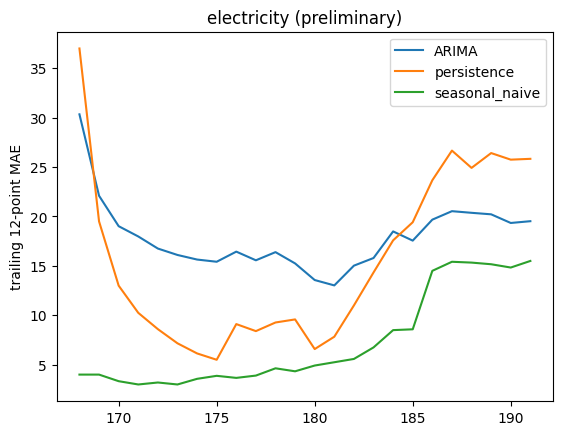

In [2]:
chosen=select(series,cfg) if series else []
label='electricity' if chosen else 'synthetic_stationary_diagnostic'
y=chosen[0]['values'] if chosen else processes(cfg)['stationary']['values']
index=chosen[0]['index'] if chosen else None
t0=time.perf_counter()
pred,report=run_stream(y,cfg,OUT/'pilot'/label,timestamps=index,provenance=stream_provenance(chosen[0]['id'] if chosen else label,y))
wall=time.perf_counter()-t0
display(metrics(pred)); metrics(pred).to_csv(OUT/'pilot_metrics.csv',index=False)
print('Dataset:',label,'loop seconds:',report['elapsed_seconds'],'sampled RSS MB:',report['peak_sampled_rss_mb'])
print('Baseline-only table above; DNH-inspired measurements follow below.')
print('Fit trials:',report['trials'])
print('Update failures:',sum(e['kind']=='update_failure' for e in report['events']))
print('Nonfinite forecasts:',int((~np.isfinite(pred.prediction)).sum()))
for model,g in pred.groupby('model'):
    plt.plot(g.t,g.abs_error.rolling(12,min_periods=1).mean(),label=model)
plt.legend(); plt.ylabel('trailing 12-point MAE'); plt.title(label+' (preliminary)')
plt.savefig(OUT/'pilot_rolling_mae.png',bbox_inches='tight'); plt.show()

## Cost estimate
Use the measured loop time as a diagnostic estimate only. It excludes initial order selection; process RSS includes interpreter and plots and is sampled, not an allocation peak. ARIMA expanding-history updates and refits can become more expensive with length; linear extrapolation is optimistic. This baseline timing cannot estimate DNH-inspired training costs; those are measured separately below. A pilot-mode measurement is still needed before budgeting the full study.

In [3]:
target=config('full')
factor=target['steps']*target['series']/cfg['steps']
estimate={'measured_stream_seconds':report['elapsed_seconds'],
          'optimistic_baseline_full_seconds':report['elapsed_seconds']*factor,
          'assumptions':'same cost per step as this small single series; sequential runs; excludes tuning/order selection, ignores length-dependent costs; not DNH estimate'}
print(estimate)
(OUT/'cost_estimate.json').write_text(json.dumps(estimate,indent=2))

{'measured_stream_seconds': 0.26779528199995184, 'optimistic_baseline_full_seconds': 241.01575379995666, 'assumptions': 'same cost per step as this small single series; sequential runs; excludes tuning/order selection, ignores length-dependent costs; not DNH estimate'}


277

## DNH-inspired v1: assumptions and bounded pilot
Read docs/DNH_INSPIRED.md before interpreting this model. Six-dimensional nested memories, separate local objectives, gated state, EAdam-like level updates and finite-difference meta probes replace unspecified details. Random features/gates are seeded; no GPU is used. Hyperparameters are fixed before this run, not tuned on evaluation. A fixed counterpart freezes topology and frequencies while retaining the same memories and inner optimizer. Three independent model seeds are reported separately. Events include development changes; evaluation counts are distinguished in the saved study tables.

adaptive 17 seconds including development 0.10063288999981523 RSS MB 642.0546875 growth 0 pruning 0


fixed 17 seconds including development 0.1044517029997678 RSS MB 642.296875 growth 0 pruning 0


adaptive 29 seconds including development 0.11569921899990732 RSS MB 642.296875 growth 0 pruning 0


fixed 29 seconds including development 0.06644777700012128 RSS MB 642.296875 growth 0 pruning 0


adaptive 43 seconds including development 0.09244244900014564 RSS MB 642.296875 growth 0 pruning 0
fixed 43 seconds including development 0.07492580800021642 RSS MB 642.296875 growth 0 pruning 0


,model,n_scored,n_unscored,MAE,RMSE,MASE,fallback_count,seed
0,DNH-inspired:adaptive,24,0,17.726595,23.598567,0.884794,0,17
1,DNH-inspired:fixed,24,0,17.801050,23.579427,0.888510,0,17
2,DNH-inspired:adaptive,24,0,17.765172,23.416030,0.886719,0,29
3,DNH-inspired:fixed,24,0,17.775747,23.374058,0.887247,0,29
4,DNH-inspired:adaptive,24,0,17.274301,23.485460,0.862218,0,43
5,DNH-inspired:fixed,24,0,17.301001,23.490884,0.863551,0,43


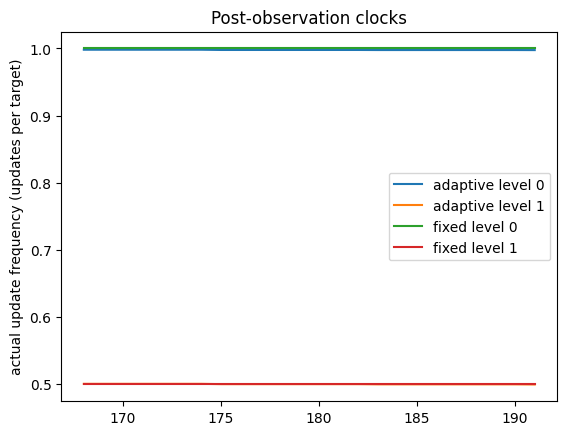

DNH-inspired preliminary only. Zero accepted structural changes is a result, not evidence that adaptation helps.
Optimistic inspired full seconds per seed/variant: 16.858306800048695


In [4]:
inspired_rows=[]
for model_seed in inspired_config()['seeds']:
    for variant in ['adaptive','fixed']:
        ip,ir=run_inspired(y,cfg,OUT/'inspired_pilot'/str(model_seed)/variant,
                          seed=model_seed,variant=variant,timestamps=index,provenance=stream_provenance(chosen[0]['id'] if chosen else label,y))
        mm=metrics(ip); mm['seed']=model_seed; inspired_rows.append(mm)
        print(variant,model_seed,'seconds including development',ir['elapsed_seconds'],
              'RSS MB',ir['peak_sampled_rss_mb'],'growth',ir['growth_count'],'pruning',ir['pruning_count'])
        st=pd.read_csv(OUT/'inspired_pilot'/str(model_seed)/variant/'structure.csv')
        if model_seed==inspired_config()['seeds'][0]:
            for uid,g in st.groupby('uid'): plt.plot(g.t,g.frequency,label=f'{variant} level {uid}')
comparison=pd.concat(inspired_rows,ignore_index=True)
display(comparison); comparison.to_csv(OUT/'inspired_pilot_metrics.csv',index=False)
plt.legend();plt.ylabel('actual update frequency (updates per target)');plt.title('Post-observation clocks')
plt.savefig(OUT/'inspired_pilot_frequencies.png',bbox_inches='tight');plt.show()
print('DNH-inspired preliminary only. Zero accepted structural changes is a result, not evidence that adaptation helps.')
# Explicit optimistic cost extrapolation, not an automatic full-run launch.
print('Optimistic inspired full seconds per seed/variant:',ir['elapsed_seconds'] *
      config('full')['series'] * (config('full')['development']+config('full')['steps']) /
      (cfg['development']+cfg['steps']))